In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_train = np.array([
    [2, 5],
    [3, 6],
    [7, 8],
    [8, 7],
    [6, 6]
])

y_train = np.array([0, 0, 1, 1, 1])

new_student = np.array([5, 7])

In [2]:
def euclidean_distance(point_a, point_b):
    difference = point_a - point_b
    squared_difference = difference ** 2

    distance = np.sqrt(
        np.sum(squared_difference)
    )

    return distance

In [3]:
distance = euclidean_distance(
    new_student,
    X_train[0]
)

print("Distance:", distance)

Distance: 3.605551275463989


In [4]:
distances = []

for point in X_train:
    distance = euclidean_distance(
        new_student,
        point
    )

    distances.append(distance)

distances = np.array(distances)

print(distances)

[3.60555128 2.23606798 2.23606798 3.         1.41421356]


In [5]:
k = 3

# Get indices of K smallest distances
nearest_indices = np.argsort(distances)[:k]

print("Nearest neighbour indices:", nearest_indices)
print("Nearest neighbour classes:", y_train[nearest_indices])

Nearest neighbour indices: [4 1 2]
Nearest neighbour classes: [1 0 1]


In [6]:
nearest_labels = y_train[nearest_indices]

predicted_class = np.bincount(
    nearest_labels
).argmax()

print("Predicted class:", predicted_class)

Predicted class: 1


In [7]:
class KNNClassifier:

    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # Store training observations and their labels
        self.X_train = np.array(X)
        self.y_train = np.array(y)

        # Validate K
        if self.k < 1 or self.k > len(self.X_train):
            raise ValueError("Invalid value of k")

    def predict(self, X):
        X = np.array(X)

        predictions = []

        for query_point in X:

            # Calculate distance from query to every training point
            distances = []

            for train_point in self.X_train:
                distance = euclidean_distance(query_point, train_point)
                distances.append(distance)

            distances = np.array(distances)

            # Find indices of the K nearest neighbours
            nearest_indices = np.argsort(distances)[:self.k]

            # Get labels of nearest neighbours
            nearest_labels = self.y_train[nearest_indices]

            # Majority voting
            classes, counts = np.unique(
                nearest_labels,
                return_counts=True
            )

            predicted_class = classes[np.argmax(counts)]

            predictions.append(predicted_class)

        return np.array(predictions)

In [8]:
knn = KNNClassifier(k=3)

knn.fit(X_train, y_train)

prediction = knn.predict([new_student])

print("Predicted class:", prediction[0])

Predicted class: 1


In [9]:
new_students = np.array([
    [5, 7],
    [2, 5],
    [8, 8]
])

predictions = knn.predict(new_students)

print(predictions)

[1 0 1]


In [10]:
X_unscaled = np.array([
    [20, 300000],
    [25, 400000],
    [30, 500000],
    [35, 600000]
])

query = np.array([28, 450000])

for point in X_unscaled:
    print(euclidean_distance(query, point))

150000.00021333335
50000.00009
50000.00004
150000.00016333334


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_unscaled)

query_scaled = scaler.transform(
    query.reshape(1, -1)
)

print("Scaled training data:")
print(X_scaled)

print("\nScaled query:")
print(query_scaled)

Scaled training data:
[[-1.34164079 -1.34164079]
 [-0.4472136  -0.4472136 ]
 [ 0.4472136   0.4472136 ]
 [ 1.34164079  1.34164079]]

Scaled query:
[[0.08944272 0.        ]]


In [12]:
k_values = [1, 3, 5]

for k in k_values:
    knn = KNNClassifier(k=k)
    knn.fit(X_train, y_train)

    prediction = knn.predict([new_student])

    print(f"K = {k}, Prediction = {prediction[0]}")

K = 1, Prediction = 1
K = 3, Prediction = 1
K = 5, Prediction = 1


## REAL DATASET KNN


In [13]:
from sklearn.datasets import load_wine

wine = load_wine()

X = wine.data
y = wine.target

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Feature names:")
print(wine.feature_names)

print("Target classes:")
print(wine.target_names)

Feature shape: (178, 13)
Target shape: (178,)
Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target classes:
['class_0' 'class_1' 'class_2']


In [14]:
import pandas as pd

class_counts = pd.Series(y).value_counts().sort_index()

print(class_counts)

0    59
1    71
2    48
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)

y_pred = knn_pipeline.predict(X_test)

In [17]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=wine.target_names
    )
)

Accuracy: 0.9722222222222222

Confusion Matrix:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      0.93      0.96        14
     class_2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



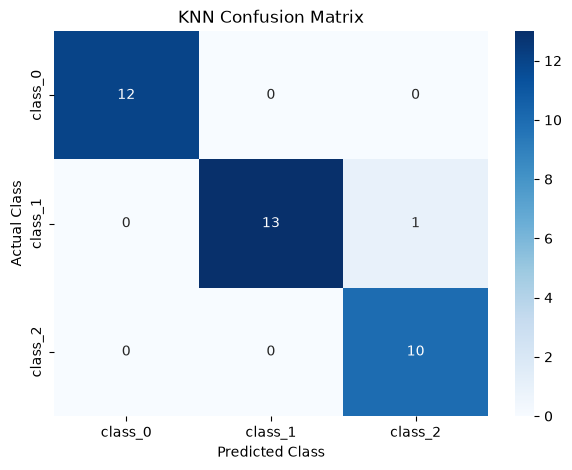

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")

plt.show()

In [19]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 22, 2)

cv_results = []

for k in k_values:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "K": k,
        "Mean Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df)

     K  Mean Accuracy  Standard Deviation
0    1       0.936700            0.013837
1    3       0.951232            0.034977
2    5       0.965025            0.037779
3    7       0.950985            0.035372
4    9       0.965025            0.037779
5   11       0.972167            0.040259
6   13       0.965025            0.037779
7   15       0.972167            0.040259
8   17       0.979064            0.027713
9   19       0.971921            0.025943
10  21       0.971921            0.025943


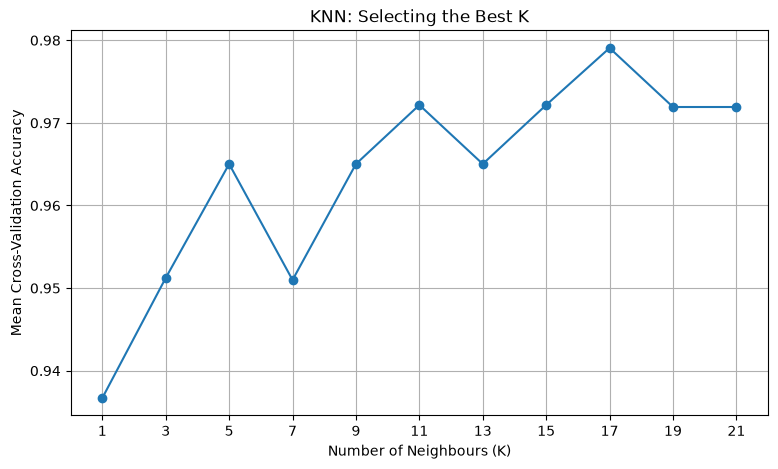

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    cv_df["K"],
    cv_df["Mean Accuracy"],
    marker="o"
)

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("KNN: Selecting the Best K")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [21]:
best_k = 17

final_knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

final_knn_pipeline.fit(X_train, y_train)

final_predictions = final_knn_pipeline.predict(X_test)

In [22]:
from sklearn.metrics import accuracy_score, classification_report

final_accuracy = accuracy_score(y_test, final_predictions)

print("Best K:", best_k)
print("Final Test Accuracy:", final_accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=wine.target_names
    )
)

Best K: 17
Final Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [23]:
print("K = 5 accuracy:",
      accuracy_score(y_test, y_pred))

print("K = 17 accuracy:",
      accuracy_score(y_test, final_predictions))

K = 5 accuracy: 0.9722222222222222
K = 17 accuracy: 1.0


In [24]:
weighted_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=17,
        weights="distance"
    ))
])

weighted_knn.fit(X_train, y_train)

weighted_predictions = weighted_knn.predict(X_test)

print(
    "Weighted KNN accuracy:",
    accuracy_score(y_test, weighted_predictions)
)

Weighted KNN accuracy: 1.0


In [25]:
distance_metrics = ["euclidean", "manhattan"]

for metric in distance_metrics:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=17,
            metric=metric
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print(
        metric,
        accuracy_score(y_test, predictions)
    )

euclidean 1.0
manhattan 0.9722222222222222


In [26]:
sample_index = 0

new_wine = X_test[sample_index].reshape(1, -1)
actual_class = y_test[sample_index]

predicted_class = final_knn_pipeline.predict(new_wine)[0]

print("Actual class:", wine.target_names[actual_class])
print("Predicted class:", wine.target_names[predicted_class])

Actual class: class_0
Predicted class: class_0


In [27]:
probabilities = final_knn_pipeline.predict_proba(new_wine)[0]

for class_name, probability in zip(
    wine.target_names,
    probabilities
):
    print(f"{class_name}: {probability:.4f}")

class_0: 1.0000
class_1: 0.0000
class_2: 0.0000


## Conclusion

In this experiment, I studied K-Nearest Neighbors (KNN) for
multiclass classification.

### Concepts learned
- KNN intuition and instance-based learning.
- Euclidean distance calculation.
- Majority voting.
- KNN implementation from scratch using NumPy.
- Feature scaling and its importance.
- Overfitting and underfitting based on K.
- Scikit-learn KNeighborsClassifier.
- Multiclass classification.
- Accuracy, precision, recall, F1-score and confusion matrix.
- Cross-validation for selecting K.
- Uniform and distance-weighted voting.
- Euclidean and Manhattan distance.

### Experimental findings

The Wine dataset contained 178 observations, 13 features
and 3 target classes.

The dataset was divided into training and testing sets
using an 80:20 split.

K=17 achieved the highest mean cross-validation accuracy
among the tested K values, approximately 97.91%.

The final K=17 Euclidean KNN model achieved 100% test
accuracy on the 36 test observations.

Distance-weighted KNN also achieved 100% accuracy.
Manhattan distance achieved 97.22% accuracy.

### Limitations

- KNN requires feature scaling when features have different
  numerical ranges.
- Prediction can become computationally expensive for
  large training datasets.
- Performance depends on K and the distance metric.
- Irrelevant features can negatively affect distance
  calculations.
- Results on a small test set may not generalize to all data.

### Final understanding

KNN is a non-parametric, instance-based learning algorithm.
It predicts a class by examining nearby training observations
and using their labels to make a decision.